 ================================================================================================================================================================================================

 NOTEBOOK 04 — ZHU GUARDED LWC RETRIEVAL (CLEANED)

 ================================================================================================================================================================================================



 Pipeline: load data -> 30 s time-average DWR -> dDWR/dH diagnostic ->

 Zhu **guarded** retrieval -> LWC quality checks -> LWP (3 checks only, for later comparison)



 Removed in this cleanup (all still recoverable from notebook history if needed):

   - 60 s time-averaging branch

   - Raw / un-averaged Zhu retrieval exploration (superseded by the 30 s branch, which is

     what feeds the guarded retrieval anyway)

   - Most LWP diagnostics — kept only: general LWP time series, LWP closure scatter,

     and the "spot check three profiles" comparison

   - 500-1500 m windowed retrieval experiment

   - common_mask (C1/C2) redundant second retrieval pass

 ================================================================================================================================================================================================

 ## 0. Setup

In [4]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

sys.path.append(str(Path("../src").resolve()))

# Preprocessing
from radar_lwc.preprocessing.align import align_to_reference_time
from radar_lwc.preprocessing.chirps import combine_chirps
from radar_lwc.preprocessing.clean import drop_duplicate_times
from radar_lwc.preprocessing.get_reflectivity import get_reflectivity

# Retrieval
from radar_lwc.retrieval.average_ze_time import avg_ze_time
from radar_lwc.retrieval.ddwr_dh import compute_ddwr_dh
from radar_lwc.retrieval.dielectric import epsilon_water_liebe1989
from radar_lwc.retrieval.kappa_liquid import kappa_liquid
from radar_lwc.retrieval.zhu import retrieve_lwc_zhu


In [5]:
Processed_Dataset = "20260925_pallas_raw_P02_P07_CLARA"

In [6]:
in_path = Path(f"../data/processed/{Processed_Dataset}/retrieval_input_4km_alpha_kappa_calculated.nc")
ds_retrieval = xr.open_dataset(in_path)
print(ds_retrieval)


<xarray.Dataset> Size: 347MB
Dimensions:          (Time: 17229, range: 237)
Coordinates:
  * Time             (Time) datetime64[ns] 138kB 2026-09-25T00:54:34.31400001...
  * range            (range) float64 2kB 104.3 119.3 ... 3.952e+03 3.986e+03
Data variables: (12/16)
    Ze_W             (Time, range) float64 33MB ...
    Ze_Ka            (Time, range) float64 33MB ...
    T_cloud          (Time, range) float64 33MB ...
    LWP              (Time) float32 69kB ...
    DWR              (Time, range) float64 33MB ...
    cloud_mask       (Time, range) bool 4MB ...
    ...               ...
    alpha_W          (Time, range) float64 33MB ...
    alpha_Ka         (Time, range) float64 33MB ...
    kappa_W          (Time, range) float64 33MB ...
    kappa_Ka         (Time, range) float64 33MB ...
    MeanVel_W        (Time, range) float64 33MB ...
    MeanVel_Ka       (Time, range) float64 33MB ...
Attributes:
    description:  Prepared inputs for Zhu et al. (2019) LWC retrieval with al.

 ================================================================================================================================================================================================

 ## 1. Time averaging (30 s only)



 Averaging Ze in linear space before forming DWR beats down per-gate DWR noise, which is a

 prerequisite for a physically meaningful dDWR/dH gradient. 30 s was kept as the working

 resolution; 60 s is dropped for now (barely changed the diagnostics — restore quickly by

 copying the `window_s=60` block back in if a comparison is ever needed again).

 ================================================================================================================================================================================================

In [7]:
ze_ka_avg = avg_ze_time(ds_retrieval["Ze_Ka"].sel(range=slice(0, 4000)), window_s=30)
ze_w_avg  = avg_ze_time(ds_retrieval["Ze_W"].sel(range=slice(0, 4000)),  window_s=30)

dwr_2km_smoothed = ze_ka_avg - ze_w_avg
dwr_2km_smoothed.name = "DWR"


In [8]:
# %% 1 dB gate-to-gate filter (Socuellamos): replace spikes by linear interpolation
gate_threshold = 1.0  # dB

def despike_1d(dwr_1d, threshold=1.0):
    """
    dwr_1d: 1D array along range for a single time step.
    A gate i is an outlier if it differs from BOTH neighbours by more than
    `threshold` dB in the same direction (i.e. it's a spike relative to a
    smooth profile) -> replaced by linear interpolation between i-1 and i+1.
    """
    out = dwr_1d.copy()
    n = len(dwr_1d)
    for i in range(1, n - 1):
        left = dwr_1d[i] - dwr_1d[i - 1]
        right = dwr_1d[i] - dwr_1d[i + 1]
        is_spike = (
            np.abs(left) > threshold
            and np.abs(right) > threshold
            and np.sign(left) == np.sign(right)   # same direction on both sides
        )
        if is_spike and not (np.isnan(dwr_1d[i - 1]) or np.isnan(dwr_1d[i + 1]) or np.isnan(dwr_1d[i])):
            out[i] = dwr_1d[i - 1] + (dwr_1d[i + 1] - dwr_1d[i - 1]) * 0.5  # linear interp
    return out

dwr_2km_filt = xr.apply_ufunc(
    despike_1d,
    dwr_2km_smoothed,
    input_core_dims=[["range"]],
    output_core_dims=[["range"]],
    kwargs={"threshold": gate_threshold},
    vectorize=True,
)
dwr_2km_filt.name = "DWR"
dwr_2km_filt.attrs = dwr_2km_smoothed.attrs

n_replaced = int((np.abs(dwr_2km_filt - dwr_2km_smoothed) > 1e-9).sum())
print(f"Gates replaced by interpolation: {n_replaced} "
      f"({n_replaced / dwr_2km_smoothed.size:.2%} of all gates)")

Gates replaced by interpolation: 1892 (0.05% of all gates)


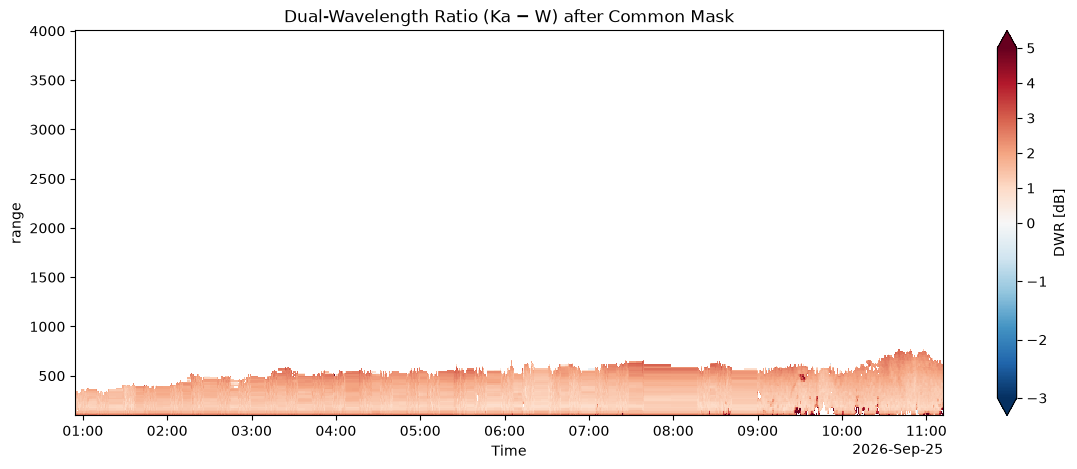

In [9]:
from matplotlib.colors import TwoSlopeNorm

fig, ax = plt.subplots(figsize=(14, 5))

dwr_2km_filt.where(ds_retrieval["common_mask"]).plot(
    x="Time",
    y="range",
    cmap="RdBu_r",
    norm=TwoSlopeNorm(vmin=-3, vcenter=0, vmax=5),
    ax=ax,
    cbar_kwargs={"label": "DWR [dB]"}
)

ax.set_title("Dual-Wavelength Ratio (Ka − W) after Common Mask")
plt.show()

 ================================================================================================================================================================================================

 ## 3. Zhu Guarded retrieval



 Drop-in replacement for the plain gradient retrieval: overlap-averages the window fit and

 rejects windows that are too noisy (`max_window_std`) or produce an unphysical gradient

 (`max_ddwr_dh`), with `edge_pad` gates skipped near cloud base/top.

 ================================================================================================================================================================================================

In [ ]:
lwc_guarded, derivative_guarded, m_eff, n_windows, n_used= retrieve_lwc_zhu( 
    dwr=dwr_2km_filt,
    kappa_w=ds_retrieval["kappa_W"],
    kappa_ka=ds_retrieval["kappa_Ka"],
    alpha_w=ds_retrieval["alpha_W"],
    alpha_ka=ds_retrieval["alpha_Ka"],
    cloud_mask=ds_retrieval["common_mask"],
    N_default=13,
    min_cloud_gates=3,
    max_ddwr_dh=30.0,
    max_window_std=1,
    edge_pad_bottom=2,         # was edge_pad=0
    edge_pad_top=1,
)

print(f"Gates with any retrieval: {int((n_windows > 0).sum())} "
      f"({100*float((n_windows>0).mean()):.1f}%)")
print(f"Mean windows per gate:    {float(n_windows.where(n_windows>0).mean()):.1f}")


Gates with any retrieval: 457058 (11.2%)
Mean windows per gate:    7.1


## Interior vs Outer edges Noise

In [ ]:
# Edge-gate noise: std of adjacent-gate DWR differences, by pair position from cloud base / top
TR   = lambda a: a.transpose("Time", "range")
dwr  = TR(dwr_2km_filt)
msk  = TR(ds_retrieval["common_mask"]).reindex_like(dwr).fillna(0).astype(bool)   # same grid as dwr
x    = np.where(msk.values, dwr.values, np.nan)
d    = np.diff(x, axis=1)                         # pair k = gates (k, k+1); NaN if either is outside cloud

MAX_POS = 6                                       # pairs counted from each edge
from_base = [[] for _ in range(MAX_POS)]
from_top  = [[] for _ in range(MAX_POS)]
interior  = []
for t in range(x.shape[0]):
    idx = np.flatnonzero(msk.values[t])
    if idx.size < 2 * MAX_POS + 2:                # only clouds thick enough to have a real interior
        continue
    lo, hi = idx[0], idx[-1]
    for k in range(lo, hi):
        if not np.isfinite(d[t, k]):
            continue
        pb, pt = k - lo, (hi - 1) - k             # 0 = pair touching base / top
        if pb < MAX_POS:   from_base[pb].append(d[t, k])
        elif pt < MAX_POS: from_top[pt].append(d[t, k])
        else:              interior.append(d[t, k])

s_int = np.std(interior) / np.sqrt(2)
print(f"interior: sigma = {s_int:.3f} dB  (n={len(interior)})\n")
print(f"{'pair':>6}{'from base':>12}{'ratio':>7}{'from top':>12}{'ratio':>7}")
for p in range(MAX_POS):
    sb = np.std(from_base[p]) / np.sqrt(2); st = np.std(from_top[p]) / np.sqrt(2)
    print(f"{p+1:>6}{sb:>12.3f}{sb/s_int:>7.2f}{st:>12.3f}{st/s_int:>7.2f}")


# Pair 1 is the base gate and the one above it, pair 2 the next one up, and so on. The same counting from the top.
#Pad as many gates as there are pairs whose ratio is clearly above 1 (say > 1.3)
#If the bottom shows two noisy pairs and the top one, that’s your (2,1). Run it per day and put the ratios in the edge-gate table or the appendix.

interior: sigma = 0.077 dB  (n=289061)

  pair   from base  ratio    from top  ratio
     1       0.493   6.41       0.468   6.08
     2       0.330   4.29       0.199   2.59
     3       0.308   4.01       0.112   1.45
     4       0.234   3.04       0.085   1.10
     5       0.199   2.58       0.073   0.95
     6       0.167   2.18       0.079   1.03


 ================================================================================================================================================================================================

 ## 4. LWC quality checks (kept: LWC<0, LWC maps, dDWR/dH already above, + 2 supporting graphs)

 ================================================================================================================================================================================================

 ### 4a. LWC < 0  (cell 23)

In [16]:
print(f"Fraction LWC < 0: "
      f"{float((lwc_guarded < 0).sum() / lwc_guarded.notnull().sum()):.2%}")
print(f"LWC quantiles: "
      f"p05={float(lwc_guarded.quantile(0.05)):.2f}, "
      f"p50={float(lwc_guarded.quantile(0.5)):.2f}, "
      f"p95={float(lwc_guarded.quantile(0.95)):.2f} g/m^3")


Fraction LWC < 0: 18.75%
LWC quantiles: p05=-0.69, p50=0.28, p95=0.82 g/m^3


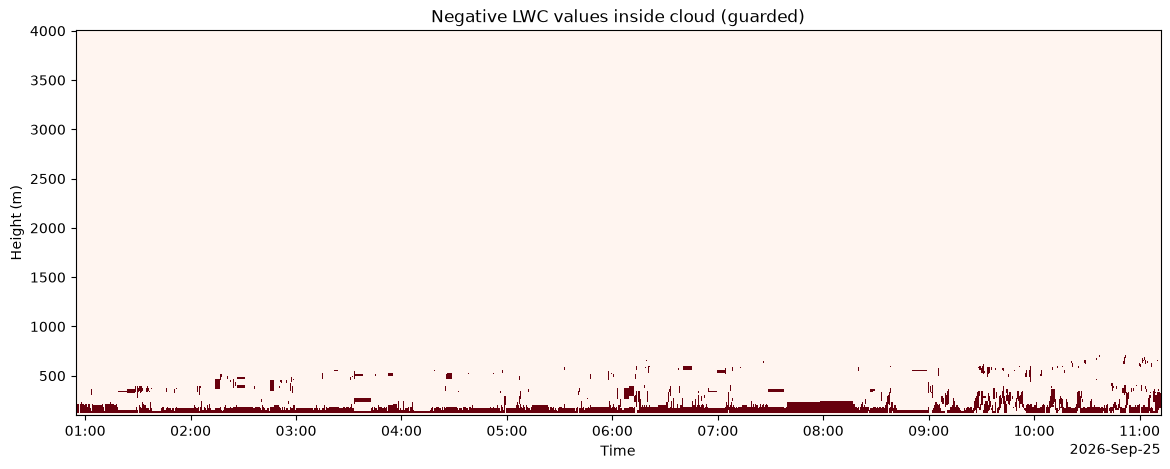

In [17]:
negative_lwc = (lwc_guarded < 0) & ds_retrieval["common_mask"]

plt.figure(figsize=(14, 5))
negative_lwc.astype(int).plot(x="Time", y="range", cmap="Reds", add_colorbar=False)
plt.title("Negative LWC values inside cloud (guarded)")
plt.xlabel("Time"); plt.ylabel("Height (m)")
plt.show()


 ### 4b. LWC map (main output)

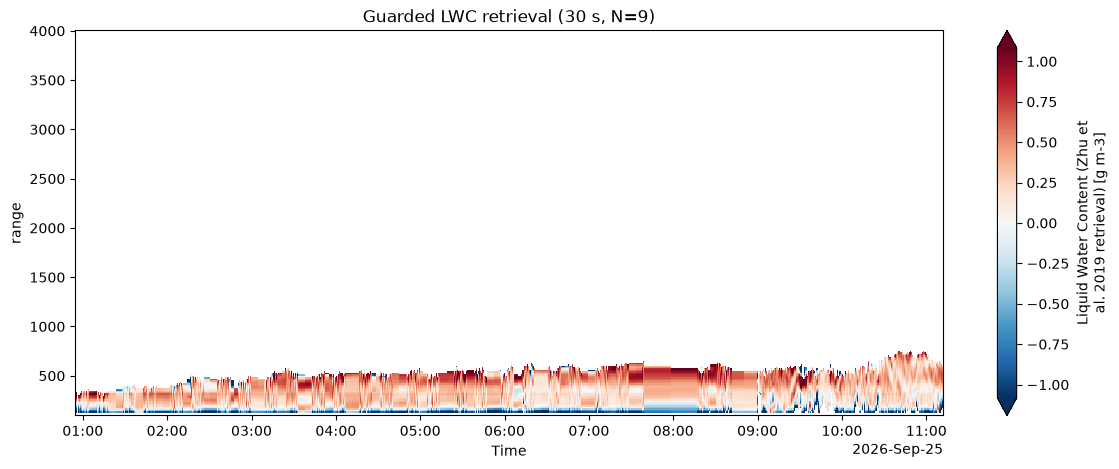

In [18]:
lwc_guarded.plot(
    x="Time", y="range", figsize=(14, 5), cmap="RdBu_r", robust=True,
)
plt.title("Guarded LWC retrieval (30 s, N=9)")
plt.show()


 ### 4c. Two supporting graphs: LWC distribution + negative-gradient locations

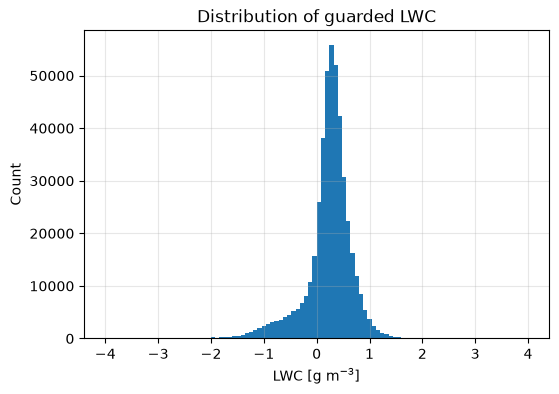

In [20]:
vals = lwc_guarded.where(ds_retrieval["common_mask"]).values
vals = vals[np.isfinite(vals)]

plt.figure(figsize=(6, 4))
plt.hist(vals, bins=100, range=(-4, 4))
plt.xlabel("LWC [g m$^{-3}$]")
plt.ylabel("Count")
plt.title("Distribution of guarded LWC")
plt.grid(alpha=0.3)
plt.show()


 ================================================================================================================================================================================================

 ## 5. LWP — kept only for later comparison (general chart, closure scatter, 3-profile spot check)

 ================================================================================================================================================================================================

 ### 5a. General LWP chart

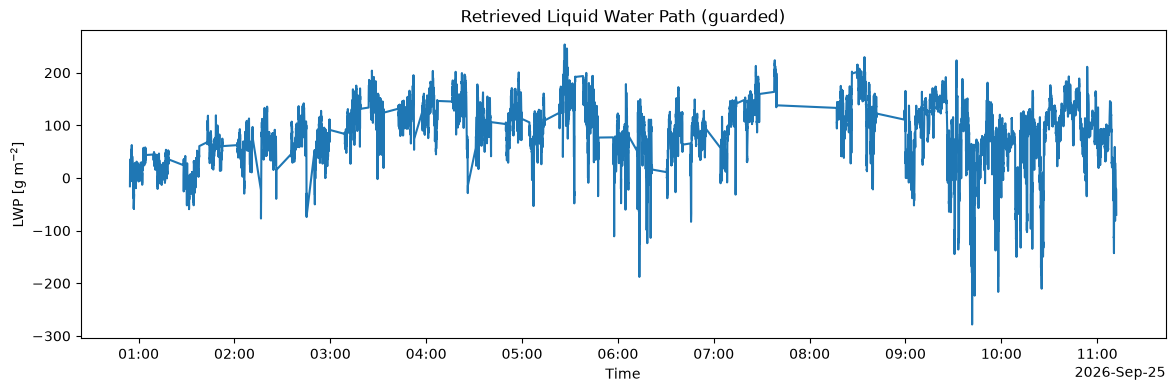

In [22]:
dz = xr.DataArray(np.gradient(dwr_2km_filt["range"].values),
                  dims="range", coords={"range": dwr_2km_filt["range"]})
lwp_guarded = (lwc_guarded.where(ds_retrieval["common_mask"]).fillna(0) * dz).sum(dim="range")
lwp_guarded = lwp_guarded.where(ds_retrieval["common_mask"].any(dim="range"))
lwp_guarded.attrs["units"] = "g m-2"

fig, ax = plt.subplots(figsize=(14, 4))
lwp_guarded.plot(ax=ax)
ax.set_title("Retrieved Liquid Water Path (guarded)")
ax.set_ylabel("LWP [g m$^{-2}$]")
ax.set_xlabel("Time")
plt.show()


 ### 5b. LWP closure test (scatter vs MWR)

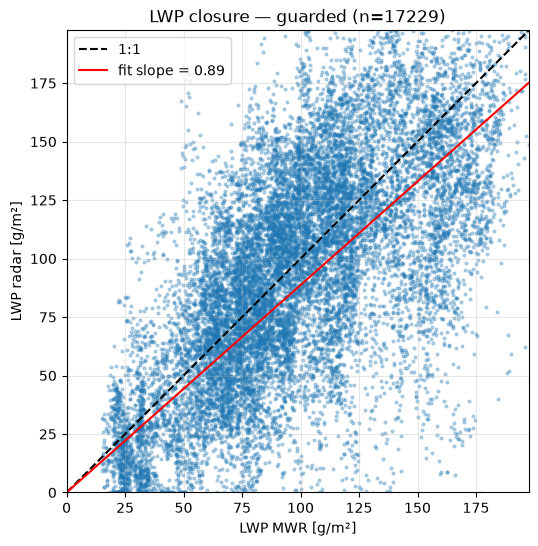

Slope through origin: 0.89   (want ~1.0)
Correlation:          0.59   (want > 0.7)
Bias:  radar - MWR = -10.0 g/m²


In [23]:
x = ds_retrieval["LWP"].values
y = lwp_guarded.values
good = np.isfinite(x) & np.isfinite(y) & (x > 5)   # ignore near-zero MWR

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(x[good], y[good], s=4, alpha=0.3)
lim = max(np.nanpercentile(x[good], 99), np.nanpercentile(y[good], 99))
ax.plot([0, lim], [0, lim], "k--", label="1:1")
slope = np.nansum(x[good] * y[good]) / np.nansum(x[good] ** 2)
ax.plot([0, lim], [0, slope * lim], "r-", label=f"fit slope = {slope:.2f}")
ax.set_xlabel("LWP MWR [g/m²]"); ax.set_ylabel("LWP radar [g/m²]")
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.legend()
ax.set_title(f"LWP closure — guarded (n={good.sum()})")
plt.show()

corr = np.corrcoef(x[good], y[good])[0, 1]
print(f"Slope through origin: {slope:.2f}   (want ~1.0)")
print(f"Correlation:          {corr:.2f}   (want > 0.7)")
print(f"Bias:  radar - MWR = {np.nanmean(y[good] - x[good]):+.1f} g/m²")


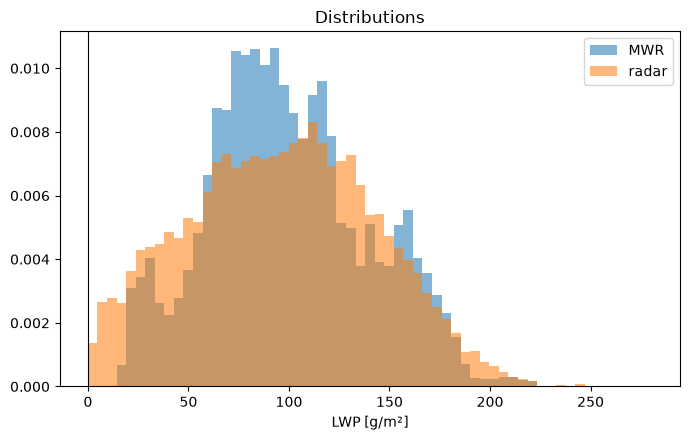

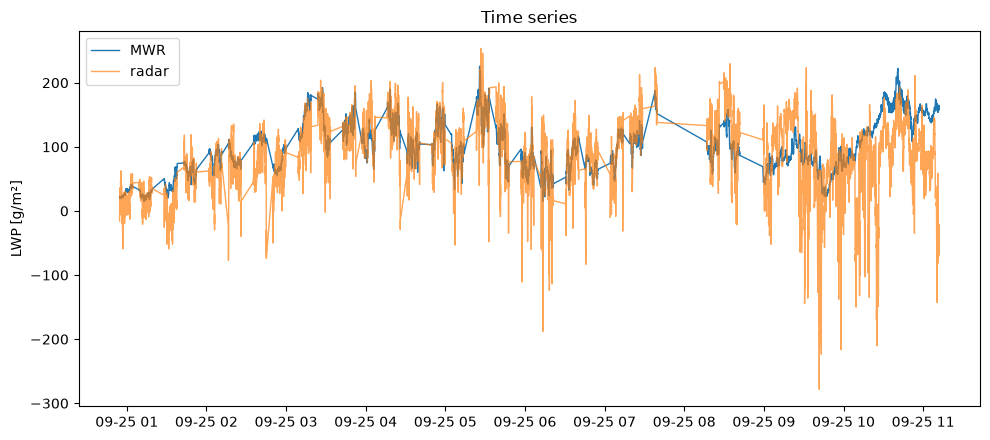

MWR   : mean   +99.6 std   39.9 p05   +32.3 p50   +95.7 p95  +169.1
radar : mean   +96.4 std   46.4 p05   +20.5 p50   +97.1 p95  +172.4


In [34]:
# %% Distribution comparison, not just scatter
x = ds_retrieval["LWP"].values
y = lwp_guarded.values
good = np.isfinite(x) & np.isfinite(y) & (y > 2)

bins = np.linspace(min(np.nanpercentile(y[good], 1), 0), np.nanpercentile(x[good], 99) * 1.5, 60)

# %% Plot 1: Verteilungen (Histogramm)
plt.figure(figsize=(7, 4.5))
plt.hist(x[good], bins=bins, alpha=0.55, label="MWR", density=True)
plt.hist(y[good], bins=bins, alpha=0.55, label="radar", density=True)
plt.axvline(0, color="k", lw=0.8); plt.legend()
plt.xlabel("LWP [g/m²]"); plt.title("Distributions")
plt.tight_layout(); plt.show()

# %% Plot 2: Zeitreihe
plt.figure(figsize=(10, 4.5))
plt.plot(ds_retrieval["Time"], x, label="MWR", lw=1)
plt.plot(ds_retrieval["Time"], y, label="radar ", lw=1, alpha=0.7)
plt.legend(); plt.ylabel("LWP [g/m²]"); plt.title("Time series")
plt.tight_layout(); plt.show()

# %% Statistik
for nm, v in [("MWR", x[good]), ("radar", y[good])]:
    print(f"{nm:6s}: mean {v.mean():+7.1f} std {v.std():6.1f} "
          f"p05 {np.percentile(v,5):+7.1f} p50 {np.percentile(v,50):+7.1f} p95 {np.percentile(v,95):+7.1f}")

In [36]:
# %% Export Zhu retrieval outputs for notebook 06
from pathlib import Path
import xarray as xr

ds_output_zhu = xr.Dataset(
    {
        "lwc_guarded":  lwc_guarded.rename("lwc_guarded"),
        "n_windows":    n_windows.rename("n_windows"),
        "dwr_filtered": dwr_2km_filt.rename("dwr_filtered"),
        "m_eff": m_eff.rename("m_eff"),
        "derivative_guarded": derivative_guarded.rename("derivative_guarded"),
        "n_used": n_used.rename("n_used")
        
    },
    attrs={
        "description": "Zhu et al. (2019) guarded retrieval output",
        "N_default": 13,                    # was 9
        "max_ddwr_dh": 30.0,                # add
        "max_window_std": 1.0,              # add
        "edge_pad_bottom": 2,               # add
        "edge_pad_top": 1,                  # add
        "input_dwr": "30 s averaged, 1 dB despiked",
        "mask_used": "common_mask",
        "created_by": "04_zhu_guarded_retrieval_CLEANED.ipynb",
    },
)

out_path = Path(f"../data/processed/{Processed_Dataset}/retrieval_output_zhu.nc")
out_path.parent.mkdir(parents=True, exist_ok=True)
ds_output_zhu.to_netcdf(out_path)
print(f"Saved → {out_path}")

Saved → ..\data\processed\20260925_pallas_raw_P02_P07_CLARA\retrieval_output_zhu.nc


## Comparison of different number of Gates N

In [ ]:
# =====================================================================
# WINDOW-SIZE SWEEP — two rounds: no padding, and (bottom=2, top=1) cell 46
# =====================================================================
N_VALUES = [5, 7, 9, 11, 13, 17, 21]
PAD_SETS = [(0, 0), (2, 1)]
MAX_DDWR = 30.0
SIG_DWR_DB = 0.223          # interior per-gate DWR noise

# The window std is signal + noise in quadrature. The signal part grows with
# the window span (so with N), the noise part doesn't. Scale accordingly,
# calibrated so threshold(N=13) = 1.0 dB, i.e. your production value.
K_SIGNAL = np.sqrt(max(1.0**2 - SIG_DWR_DB**2, 0.0)) / 13.0

STD_MODE = "scaled"         # "scaled" | "fixed" (1.0 for all N) | "off"

def std_threshold(N):
    if STD_MODE == "off":   return 1e9
    if STD_MODE == "fixed": return 1.0
    return float(np.sqrt((K_SIGNAL * N) ** 2 + SIG_DWR_DB ** 2))

cmask = ds_retrieval["common_mask"].transpose("Time", "range")
dz    = np.gradient(dwr_2km_filt["range"].values)
dr_m  = float(np.median(np.diff(dwr_2km_filt["range"].values)))
dk    = float((ds_retrieval["kappa_W"] - ds_retrieval["kappa_Ka"])
              .where(cmask).median())

assert dwr_2km_filt.transpose("Time", "range").shape == cmask.shape, \
    "dwr_2km_filt is not on the mask grid - restart the kernel"

print(f"gate {dr_m:.1f} m | dkappa {dk:.2f} dB/km/(g/m3) | std mode '{STD_MODE}'")

sweep_N = {}
for pb, pt in PAD_SETS:
    for N in N_VALUES:
        thr = std_threshold(N)
        lwc, *_ = retrieve_lwc_zhu(
            dwr=dwr_2km_filt,
            kappa_w=ds_retrieval["kappa_W"],
            kappa_ka=ds_retrieval["kappa_Ka"],
            alpha_w=ds_retrieval["alpha_W"],
            alpha_ka=ds_retrieval["alpha_Ka"],
            cloud_mask=cmask,
            N_default=N, min_cloud_gates=3,
            max_ddwr_dh=MAX_DDWR, max_window_std=thr,
            edge_pad_bottom=pb, edge_pad_top=pt,
        )
        sweep_N[(pb, pt, N)] = lwc
        print(f"  pad ({pb},{pt})  N={N:>2}  span={N*dr_m:>4.0f} m  "
              f"std_thr={thr:.2f} dB  {int(np.isfinite(lwc.values).sum()):>7} gates")

gate 13.5 m | dkappa 3.66 dB/km/(g/m3) | std mode 'scaled'
  pad (0,0)  N= 5  span=  68 m  std_thr=0.44 dB   475950 gates
  pad (0,0)  N= 7  span=  95 m  std_thr=0.57 dB   484545 gates
  pad (0,0)  N= 9  span= 122 m  std_thr=0.71 dB   490876 gates
  pad (0,0)  N=11  span= 149 m  std_thr=0.85 dB   500491 gates
  pad (0,0)  N=13  span= 176 m  std_thr=1.00 dB   506086 gates
  pad (0,0)  N=17  span= 230 m  std_thr=1.29 dB   505689 gates
  pad (0,0)  N=21  span= 284 m  std_thr=1.59 dB   505588 gates
  pad (2,1)  N= 5  span=  68 m  std_thr=0.44 dB   454594 gates
  pad (2,1)  N= 7  span=  95 m  std_thr=0.57 dB   456453 gates
  pad (2,1)  N= 9  span= 122 m  std_thr=0.71 dB   457324 gates
  pad (2,1)  N=11  span= 149 m  std_thr=0.85 dB   457269 gates
  pad (2,1)  N=13  span= 176 m  std_thr=1.00 dB   457058 gates
  pad (2,1)  N=17  span= 230 m  std_thr=1.29 dB   456215 gates


In [ ]:
# --- compare ---
lwp_mwr = ds_retrieval["LWP"].values

def sigma_lwc_ols(N, sig_dwr, dr_m, dkappa):
    """OLS slope error through the retrieval equation. White-noise prediction."""
    if N < 3:
        return np.nan
    slope = sig_dwr * np.sqrt(12.0 / (N * (N**2 - 1))) / dr_m * 1000.0   # dB/km
    return 0.5 * slope / dkappa

def diagnose_N(pb, pt):
    print(f"\n=== edge pads (bottom={pb}, top={pt}) ===")
    print(f"{'N':>4}{'span':>6}{'gates':>9}{'prof':>7}{'median':>8}{'std':>7}"
          f"{'pred':>7}{'ratio':>7}{'<0':>6}{'<-1':>7}{'<-2':>7}"
          f" | {'LWPbias%':>9}{'rmse':>7}{'corr':>6}")
    for N in N_VALUES:
        L = sweep_N[(pb, pt, N)].where(cmask).values
        v = L[np.isfinite(L)]
        if v.size < 100:
            print(f"{N:>4}   too few gates ({v.size})")
            continue

        lwp_r = np.nansum(np.where(np.isfinite(L), L, 0.0) * dz, axis=1)
        lwp_r[~np.isfinite(L).any(axis=1)] = np.nan
        ok = np.isfinite(lwp_mwr) & np.isfinite(lwp_r) & (lwp_mwr > 20)

        if ok.sum() >= 30:
            bias = np.median(100 * (lwp_r[ok] - lwp_mwr[ok]) / lwp_mwr[ok])
            rmse = np.sqrt(np.mean((lwp_r[ok] - lwp_mwr[ok]) ** 2))
            corr = np.corrcoef(lwp_r[ok], lwp_mwr[ok])[0, 1]
        else:
            bias = rmse = corr = np.nan

        pred  = sigma_lwc_ols(N, SIG_DWR_DB, dr_m, dk)
        nprof = int(np.isfinite(L).any(axis=1).sum())

        print(f"{N:>4}{N*dr_m:>6.0f}{v.size:>9}{nprof:>7}{np.median(v):>8.3f}"
              f"{v.std():>7.3f}{pred:>7.3f}{v.std()/pred:>7.2f}"
              f"{(v < 0).mean():>6.0%}{(v < -1).mean():>7.1%}{(v < -2).mean():>7.1%}"
              f" | {bias:>9.1f}{rmse:>7.1f}{corr:>6.2f}")

for pb, pt in PAD_SETS:
    diagnose_N(pb, pt)


=== edge pads (bottom=0, top=0) ===
   N  span    gates   prof  median    std   pred  ratio    <0    <-1    <-2 |  LWPbias%   rmse  corr
   5    68   475950  17229   0.271  1.037  0.714   1.45   33%  11.5%   6.3% |     -71.7   97.0  0.45
   7    95   484545  17229   0.282  1.019  0.427   2.39   29%  12.0%   6.8% |     -91.2  109.6  0.46
   9   122   490876  17229   0.282  0.971  0.291   3.33   27%  12.1%   6.6% |     -93.7  113.0  0.48
  11   149   500491  17227   0.277  1.005  0.215   4.67   27%  12.9%   7.1% |    -115.1  131.2  0.44
  13   176   506086  17215   0.272  0.953  0.167   5.70   28%  12.9%   6.7% |    -115.6  127.4  0.50
  17   230   505689  17103   0.255  0.735  0.112   6.57   30%  10.2%   3.2% |     -77.3   94.0  0.58
  21   284   505588  17069   0.247  0.641  0.081   7.88   31%   8.0%   0.8% |     -53.4   76.8  0.64

=== edge pads (bottom=2, top=1) ===
   N  span    gates   prof  median    std   pred  ratio    <0    <-1    <-2 |  LWPbias%   rmse  corr
   5    68   4545

## Edge Pad analysis

In [ ]:
# --- pad sweep ---
PADS      = [(0, 0), (1, 0), (2, 0), (2, 1), (2, 2) , (3, 1), (4, 1), (5, 1), (6, 1), (4, 2), (5, 2), (6, 2), ()]
N_DEFAULT = 13
cmask     = ds_retrieval["common_mask"].transpose("Time", "range")

assert dwr_2km_filt.transpose("Time", "range").shape == cmask.shape, \
    "dwr_2km_filt is not on the mask grid - a later cell overwrote it; restart the kernel"

sweep_pad = {}
for pb, pt in PADS:
    lwc, *_ = retrieve_lwc_zhu(
        dwr=dwr_2km_filt,
        kappa_w=ds_retrieval["kappa_W"],
        kappa_ka=ds_retrieval["kappa_Ka"],
        alpha_w=ds_retrieval["alpha_W"],
        alpha_ka=ds_retrieval["alpha_Ka"],
        cloud_mask=cmask,
        N_default=N_DEFAULT, min_cloud_gates=3,
        max_ddwr_dh=20.0, max_window_std=1.0,
        edge_pad_bottom=pb, edge_pad_top=pt,
    )
    sweep_pad[(pb, pt)] = lwc
    print(f"  pad ({pb},{pt}): {int(np.isfinite(lwc.values).sum())} gates")


  pad (0,0): 490057 gates
  pad (1,0): 488733 gates
  pad (2,0): 472713 gates
  pad (2,1): 456214 gates
  pad (2,2): 439419 gates
  pad (3,1): 439681 gates
  pad (4,1): 422920 gates
  pad (5,1): 406068 gates
  pad (6,1): 389114 gates
  pad (4,2): 406156 gates
  pad (5,2): 389293 gates
  pad (6,2): 372329 gates


In [ ]:

# --- compare ---
dz       = np.gradient(dwr_2km_filt["range"].values)
lwp_mwr  = ds_retrieval["LWP"].values

base     = sweep_pad[PADS[0]].where(cmask).values
base_n   = max(int(np.isfinite(base).sum()), 1)
base_lwp = np.nansum(np.where(np.isfinite(base), base, 0.0) * dz, axis=1)
base_lwp[~np.isfinite(base).any(axis=1)] = np.nan

print(f"{'pad(b,t)':>9}{'gates':>9}{'keep%':>7}{'median':>8}{'std':>7}{'<0':>6}"
      f" | {'LWPbias%':>9}{'LWPrmse':>9}{'corr':>6}{'vs(0,0)%':>10}")
for k in PADS:
    L = sweep_pad[k].where(cmask).values
    v = L[np.isfinite(L)]
    lwp_r = np.nansum(np.where(np.isfinite(L), L, 0.0) * dz, axis=1)
    lwp_r[~np.isfinite(L).any(axis=1)] = np.nan

    ok = np.isfinite(lwp_mwr) & np.isfinite(lwp_r) & (lwp_mwr > 20)
    if v.size == 0 or ok.sum() < 30:
        print(f"{str(k):>9}  too few valid gates/profiles - skipped")
        continue

    bias = np.median(100*(lwp_r[ok] - lwp_mwr[ok]) / lwp_mwr[ok])
    rmse = np.sqrt(np.mean((lwp_r[ok] - lwp_mwr[ok])**2))
    corr = np.corrcoef(lwp_r[ok], lwp_mwr[ok])[0, 1]
    ok2  = ok & np.isfinite(base_lwp) & (base_lwp > 0)
    rel  = np.median(100*(lwp_r[ok2] - base_lwp[ok2]) / base_lwp[ok2])

    print(f"{str(k):>9}{v.size:>9}{100*v.size/base_n:>7.1f}{np.median(v):>8.3f}"
          f"{v.std():>7.3f}{(v < 0).mean():>6.0%} | {bias:>9.1f}{rmse:>9.1f}"
          f"{corr:>6.2f}{rel:>10.1f}")

 pad(b,t)    gates  keep%  median    std    <0 |  LWPbias%  LWPrmse  corr  vs(0,0)%
   (0, 0)   490057  100.0   0.271  0.651   24% |     -51.0     71.8  0.54       0.0
   (1, 0)   488733   99.7   0.271  0.639   24% |     -48.9     68.5  0.55       0.0
   (2, 0)   472713   96.5   0.277  0.455   19% |      -5.5     49.1  0.57      64.7
   (2, 1)   456214   93.1   0.280  0.437   18% |      -4.3     42.0  0.63      60.3
   (2, 2)   439419   89.7   0.272  0.433   19% |     -12.3     40.6  0.65      45.6
   (3, 1)   439681   89.7   0.298  0.339   12% |      20.8     44.7  0.64      98.6
   (4, 1)   422920   86.3   0.323  0.309    8% |      32.3     49.2  0.64     113.7
   (5, 1)   406068   82.9   0.339  0.308    7% |      33.9     49.4  0.63     112.6
   (6, 1)   389114   79.4   0.341  0.314    8% |      28.6     46.5  0.63     104.3
   (4, 2)   406156   82.9   0.317  0.295    8% |      24.8     43.1  0.65      98.7
   (5, 2)   389293   79.4   0.332  0.293    7% |      26.2     43.2  0.65   